In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import extinction
from scipy.integrate import trapezoid
from astropy.io import fits
import numpy as np

In [2]:
def gaussian_line(lam, center, flux, sigma):
    norm = flux / (sigma * np.sqrt(2 * np.pi))
    return norm * np.exp(-0.5 * ((lam - center) / sigma) ** 2)

In [3]:
def apply_extinction_odonnell(wave, spectrum, ebv,rv):
    
    av = rv * ebv
    a_lambda = extinction.odonnell94(wave, av, rv)
    attenuation_factor = 10 ** (-0.4 * a_lambda)

    return spectrum * attenuation_factor

In [4]:
def add_noise_by_halpha_flux(wave, spectrum, halpha_center, snr_halpha, window=20.0):
    mask = (wave > halpha_center - window) & (wave < halpha_center + window)
    n_pix = np.sum(mask)
    dl = np.median(np.diff(wave))

    # Halpha flux is approximately 1 before extinction/noise if normalized
    halpha_flux = trapezoid(spectrum[mask], wave[mask])

    # Desired integrated flux error
    flux_err_target = halpha_flux / snr_halpha

    # Convert integrated flux error to per-pixel noise std
    noise_std = flux_err_target / (np.sqrt(n_pix) * dl)

    noise = np.random.normal(0.0, noise_std, size=spectrum.shape)
    return spectrum + noise, noise_std

In [5]:
def sample_ngc253_ebv(size, mode="normal"):
    if mode == "fixed":
        return np.full(size, 0.36)

    if mode == "normal":
        ebv = np.random.normal(loc=0.36, scale=0.25, size=size)
        return np.clip(ebv, 0.0, 2.5)
        
    if mode == "lognorm":
        ebv = np.random.lognormal(mean=np.log(0.36), sigma=0.5, size=size)
        return np.clip(ebv, 0.0, 2.5)

In [6]:
def sample_velocity_shift(size):
    v_sys = 242.0
    v_local = np.random.uniform(-200.0, 200.0, size=size)
    return v_sys + v_local

In [7]:
def muse_sigma_v(wave_angstrom):
    
    c_kms = 299792.458
    wave = np.asarray(wave_angstrom, dtype=float)

    fwhm_angstrom = (5.866e-8 * wave**2 - 9.187e-4 * wave + 6.040)

    sigma_angstrom = fwhm_angstrom / 2.355
    sigma_v = c_kms * sigma_angstrom / wave

    return sigma_v

In [8]:
def sample_intrinsic_sigma_v(size, nebular_class):

    sigma_ranges = {"HII": (30.0, 50.0),
                    "PN":  (30.0, 50.0),
                    "DIG": (30.0, 50.0),
                    "SNR": (50.0, 150.0),}

    low, high = sigma_ranges[nebular_class]
    return np.random.uniform(low, high, size=size)

In [9]:
target_lines = {"H__1__4861A": 4861.33,
                "O__3__4959A": 4958.91,
                "O__3__5007A": 5006.84,
                "HE_1__5876A": 5875.62,
                "N__2__6548A": 6548.05,
                "H__1__6563A": 6562.80,
                "N__2__6584A": 6583.45,
                "S_II__6716A": 6716.44,
                "S_II__6731A": 6730.82,
                "O__1__6300A": 6300.00}

In [10]:
def mock_spectrum(row, wave, target_lines, sigma_intrinsic_v,  velocity_shift):
    c_kms = 299792.458
    spectrum = np.zeros_like(wave, dtype=float)

    for line_name, rest_wave in target_lines.items():
        line_flux = row[line_name]

        observed_center = rest_wave * (1.0 + velocity_shift / c_kms)
        
        sigma_muse_v_kms = muse_sigma_v(observed_center)
        sigma_total_v_kms = np.sqrt(sigma_muse_v_kms**2 + sigma_intrinsic_v**2)
        sigma_angstrom = observed_center * sigma_total_v_kms  / c_kms

        spectrum += gaussian_line(wave, observed_center, line_flux, sigma_angstrom)

    return spectrum

In [11]:
lam_min = 4600.0
lam_max = 9400.0
dl = 1.25

wave = np.arange(lam_min, lam_max + dl, dl)

In [12]:
models = pd.read_csv("models_constrained_OI.csv")
print(models["class"].value_counts())

class
DIG    6545
HII     451
SNR     296
PN      216
Name: count, dtype: int64


In [13]:
'''
spectra = []
labels = []
metadata = []


for idx, row in models.iterrows():
    neb_class = row["class"]

    ebv = sample_ngc253_ebv(1, "lognorm")[0]
    velocity_shift_kms = sample_velocity_shift(1)[0]

    sigma_intrinsic_v_kms = sample_intrinsic_sigma_v(1, nebular_class=neb_class)[0]

    spec = mock_spectrum(row, wave, target_lines, sigma_intrinsic_v_kms, velocity_shift_kms)

    spec = apply_extinction_odonnell(wave, spec, ebv, 3.1)

    halpha_center = target_lines["H__1__6563A"] * (1.0 + velocity_shift_kms / 299792.458)

    spec, noise_std = add_noise_by_halpha_flux(wave, spec, halpha_center, snr_halpha=100.0)

    if not np.all(np.isfinite(spec)):
        continue

    spectra.append(spec)
    labels.append(neb_class)

    metadata.append({
        "original_index": idx,
        "class": neb_class,
        "ebv": ebv,
        "velocity_shift_kms": velocity_shift_kms,
        "sigma_intrinsic_v_kms": sigma_intrinsic_v_kms,
        "snr_halpha": 100.0})

X = np.array(spectra)
Y = np.array(labels)
metadata = pd.DataFrame(metadata)

print(X.shape)
print(Y.shape)
print(metadata.head())

class_columns = ["HII", "PN", "SNR", "DIG"]
label_df = pd.DataFrame(0.0, index=np.arange(len(Y)), columns=class_columns)

for i, label in enumerate(Y):
    label_df.loc[i, label] = 1.0

mock_labels_metadata = pd.concat([metadata.reset_index(drop=True), label_df.reset_index(drop=True)],axis=1)
mock_labels_metadata.to_csv("mock_spectra_labels_metadata.csv", index=False)

print(mock_labels_metadata.head())'''

'\nspectra = []\nlabels = []\nmetadata = []\n\n\nfor idx, row in models.iterrows():\n    neb_class = row["class"]\n\n    ebv = sample_ngc253_ebv(1, "lognorm")[0]\n    velocity_shift_kms = sample_velocity_shift(1)[0]\n\n    sigma_intrinsic_v_kms = sample_intrinsic_sigma_v(1, nebular_class=neb_class)[0]\n\n    spec = mock_spectrum(row, wave, target_lines, sigma_intrinsic_v_kms, velocity_shift_kms)\n\n    spec = apply_extinction_odonnell(wave, spec, ebv, 3.1)\n\n    halpha_center = target_lines["H__1__6563A"] * (1.0 + velocity_shift_kms / 299792.458)\n\n    spec, noise_std = add_noise_by_halpha_flux(wave, spec, halpha_center, snr_halpha=100.0)\n\n    if not np.all(np.isfinite(spec)):\n        continue\n\n    spectra.append(spec)\n    labels.append(neb_class)\n\n    metadata.append({\n        "original_index": idx,\n        "class": neb_class,\n        "ebv": ebv,\n        "velocity_shift_kms": velocity_shift_kms,\n        "sigma_intrinsic_v_kms": sigma_intrinsic_v_kms,\n        "snr_halph

In [14]:
n_combined = 100000
rng = np.random.default_rng(42)

class_columns = ["HII", "PN", "SNR", "DIG"]

combined_spectra = []
combined_metadata = []

models_by_class = {neb_class: models[models["class"] == neb_class] for neb_class in class_columns}

for mixture_id in range(n_combined):
    #SNR_HA = 10 ** rng.uniform(np.log10(10), np.log10(200))
    SNR_HA = 10
    #SNR_HA = np.in
    
    r = rng.random()

    if r < 0.4:
        # mostly one dominant class
        weights = rng.dirichlet([0.1, 0.1, 0.1, 0.1])

    elif r < 0.8:
        # moderately mixed spectra
        weights = rng.dirichlet([1.0, 1.0, 1.0, 1.0])

    else:
        # very mixed / almost flat combinations
        weights = rng.dirichlet([5.0, 5.0, 5.0, 5.0])

    weights /= weights.sum()

    velocity_shift_kms = sample_velocity_shift(1)[0]
    ebv = sample_ngc253_ebv(1, "lognorm")[0]

    combined_spec = np.zeros_like(wave, dtype=float)
    record = {"mixture_id": mixture_id, "ebv": ebv, "velocity_shift_kms": velocity_shift_kms, "snr_halpha": SNR_HA}

    for neb_class, weight in zip(class_columns, weights):
        class_models = models_by_class[neb_class]
        source_index = rng.choice(class_models.index)
        source_row = class_models.loc[source_index]

        sigma_v = sample_intrinsic_sigma_v(1, nebular_class=neb_class)[0]

        component_spec = mock_spectrum(source_row, wave, target_lines, sigma_v, velocity_shift_kms)
        combined_spec += weight * component_spec

        record[neb_class] = weight
        #record[f"{neb_class}_source_index"] = source_index
        record[f"{neb_class}_model_id"] = source_row["model_id"]
        record[f"{neb_class}_sigma_v"] = sigma_v

    combined_spec = apply_extinction_odonnell(wave, combined_spec, ebv, 3.1)

    halpha_center = target_lines["H__1__6563A"] * (1.0 + velocity_shift_kms / 299792.458)

    combined_spec, noise_std = add_noise_by_halpha_flux(wave, combined_spec,
        halpha_center, snr_halpha=SNR_HA)

    if not np.all(np.isfinite(combined_spec)):
        continue

    record["noise_std"] = noise_std
    record["dominant_class"] = class_columns[np.argmax(weights)]
    record["dominant_weight"] = np.max(weights)

    combined_spectra.append(combined_spec.astype(np.float32))
    combined_metadata.append(record)

X_combined = np.asarray(combined_spectra, dtype=np.float32)
combined_metadata = pd.DataFrame(combined_metadata)
Y_combined = combined_metadata[class_columns].to_numpy(dtype=np.float32)

np.save("mock_spectra_combined_OI_SNR10_1e5.npy", X_combined)
np.save("mock_spectra_combined_weights_OI_SNR10_1e5.npy", Y_combined)
combined_metadata.to_csv("mock_spectra_combined_metadata_OI_SNR10_1e5.csv", index=False)

print("Combined spectra:", X_combined.shape)
print("Weights:", Y_combined.shape)

Combined spectra: (100000, 3841)
Weights: (100000, 4)


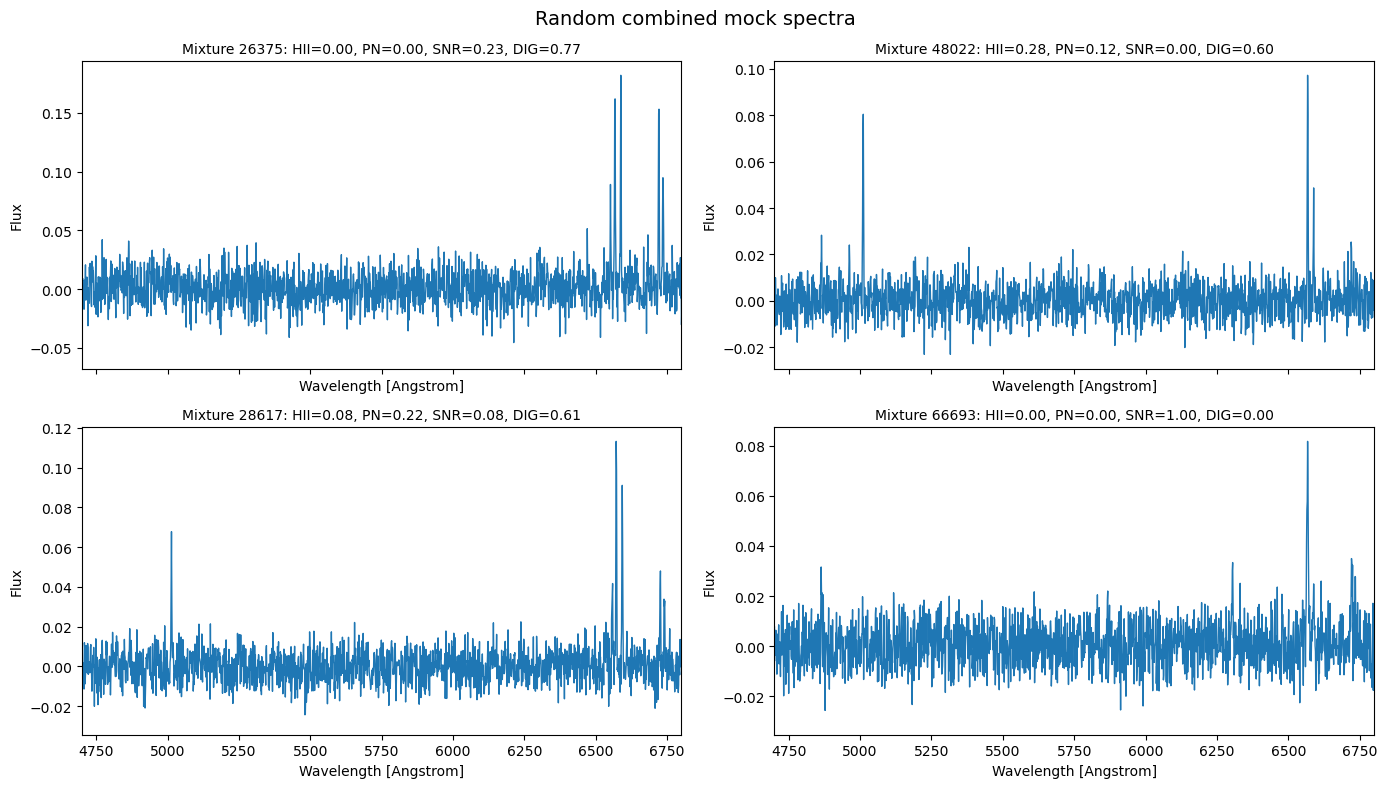

In [15]:
plot_rng = np.random.default_rng()
plot_indices = plot_rng.choice(len(X_combined), size=4, replace=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for ax, index in zip(axes.flat, plot_indices):
    ax.plot(wave, X_combined[index], linewidth=1.0)
    weight_text = ", ".join(f"{neb_class}={Y_combined[index, class_index]:.2f}" for class_index, neb_class in enumerate(class_columns))
    ax.set_title(f"Mixture {index}: {weight_text}", fontsize=10)
    ax.set_xlim(4700, 6800)
    ax.set_xlabel("Wavelength [Angstrom]")
    ax.set_ylabel("Flux")

fig.suptitle("Random combined mock spectra", fontsize=14)
fig.tight_layout()
plt.show()
